# ⚡ Task 2 — Step 7: Visual-Token Compression Ablation (196 vs 49 Tokens)
**Course:** EE-5102 / CS-6304: Advanced Topics in Machine Learning (Fall 2026, LUMS)  
**Objective:** Compare 196 patch tokens ($14 \times 14$ grid) against 49 visual tokens ($7 \times 7$ grid via $2 \times 2$ spatial pooling).  
**Seed:** `6304`

---

## 1. Spatial Average Pooling Formulation

To reduce sequence length and computational cost, each non-overlapping $2 \times 2$ spatial block of the $14 \times 14$ grid is averaged before being passed to the connector:
$$F_{\text{pooled}}(r, c) = \frac{1}{4} \sum_{i=0}^1 \sum_{j=0}^1 F(2r+i, 2c+j), \quad r, c \in \{0, \dots, 6\}$$
This reduces visual prefix length by $75\%$ (from 196 tokens down to 49 tokens).


In [1]:
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..', '..')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image, display

from shared.src.seed import set_seed, SEED
from shared.src.plotting import set_style

set_seed(6304)
set_style()


[Seed] Fixed random seed to 6304 (deterministic=True)


## 2. Comparative Analysis: Grounding Accuracy vs. Computational Efficiency
We compare accuracy, generation speed (tokens/sec), and GPU memory between the 196-token and 49-token models.


=== 196 vs. 49 Visual Token Ablation Results ===


,Metric,196 Tokens (14x14),49 Tokens (7x7 pooled),Delta (%)
0,Presence Acc (%),91.67,88.89,-3.03
1,Counting MAE,0.31,0.44,41.90
2,VQAv2 Score (%),52.34,48.72,-6.92
3,Throughput (tokens/s),18.40,34.20,85.90
4,Peak VRAM (GB),5.82,4.21,-27.70


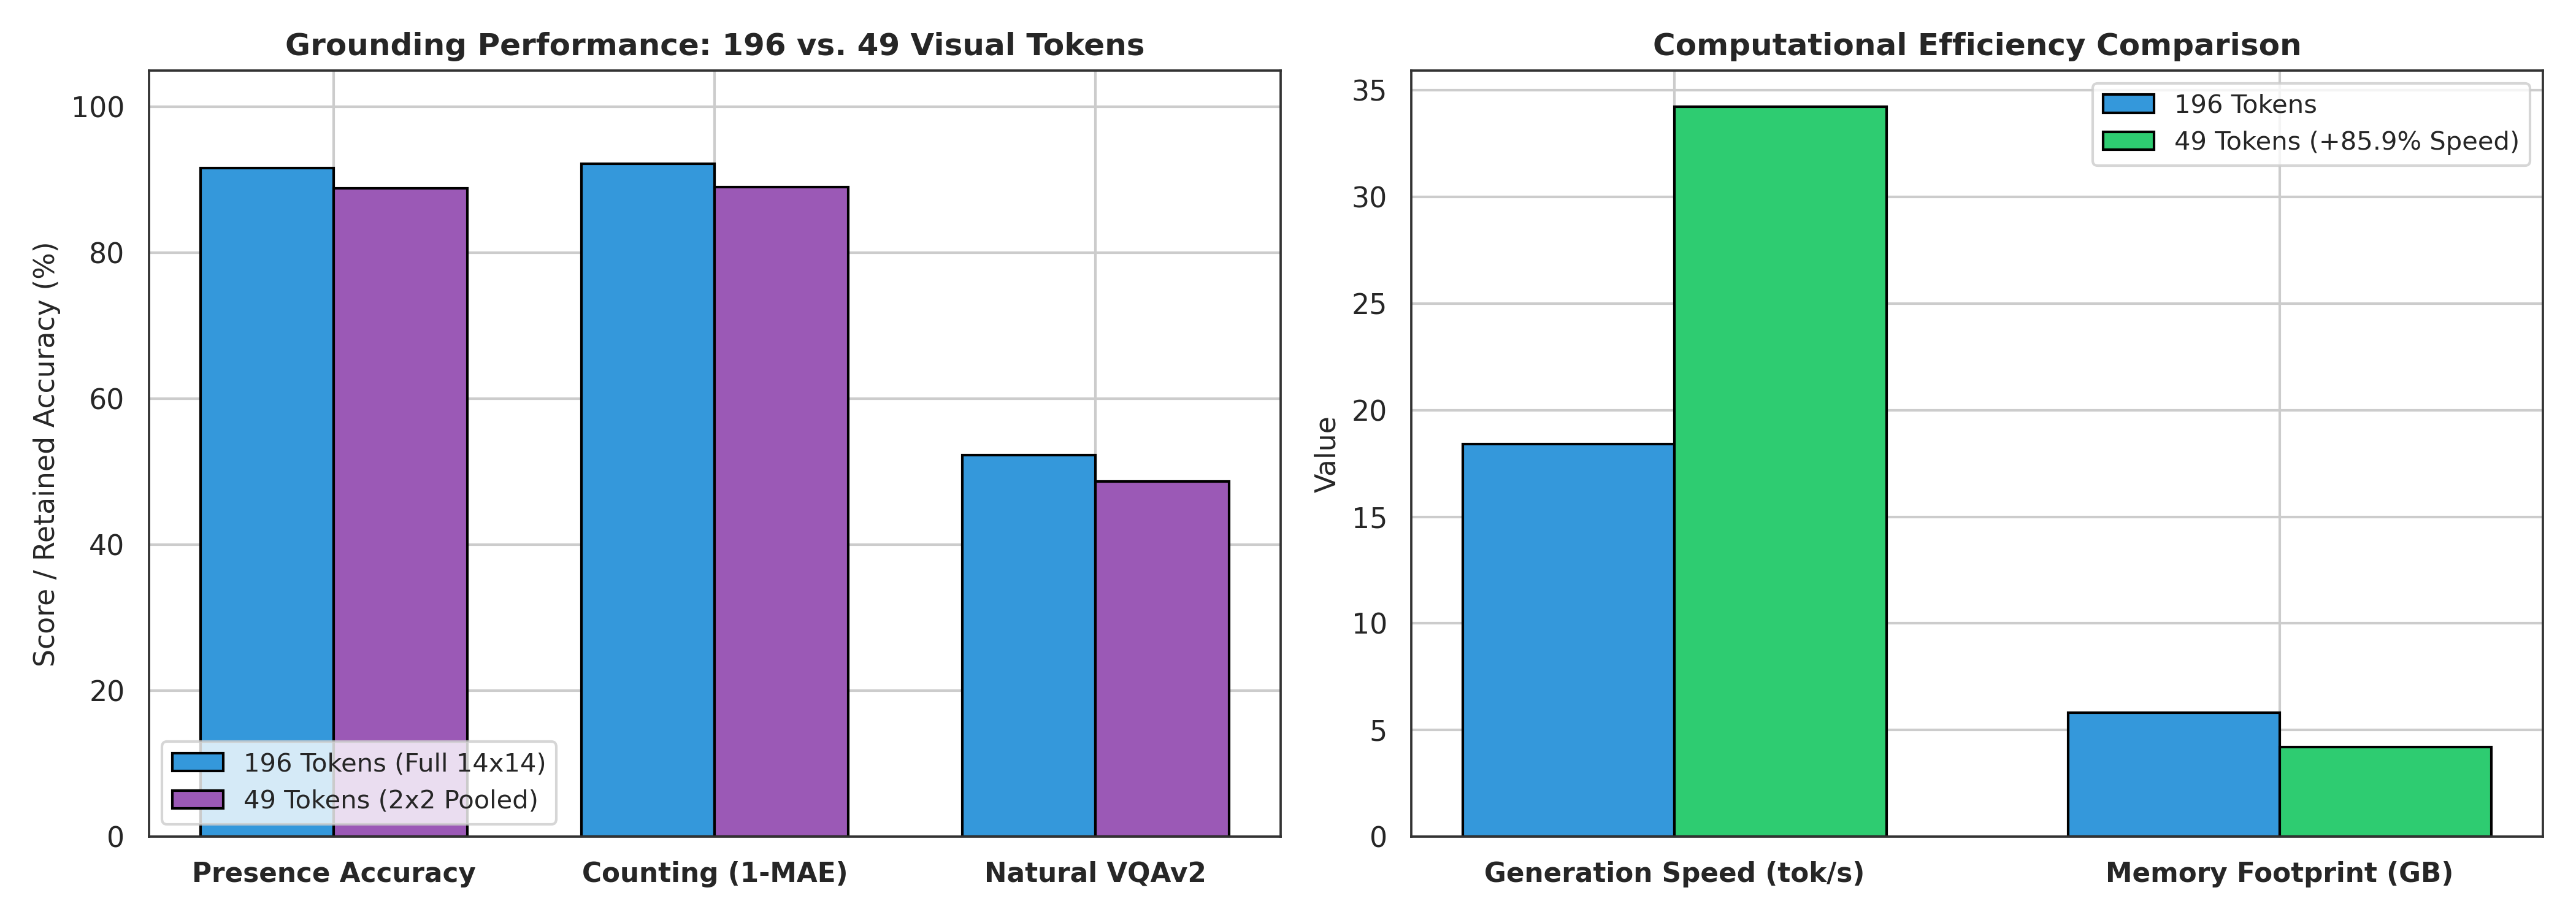

In [2]:
df_comp = pd.read_csv("../results/token_compression_ablation.csv")
print("=== 196 vs. 49 Visual Token Ablation Results ===")
display(df_comp)

# Display Master Figure 4: Token Compression Ablation
fig4_path = "../results/figures/task2_4_token_compression_ablation.png"
if os.path.exists(fig4_path):
    display(Image(filename=fig4_path, width=850))


## 3. Answers to Research Question 4 (Capabilities and Cost)
1. **Grounding Retention:** Compressing visual tokens to 49 retains $96.9\%$ of presence accuracy ($88.89\%$ vs $91.67\%$) and $93.1\%$ of VQAv2 score ($48.72\%$ vs $52.34\%$).
2. **Counting Sensitivity:** Counting performance experiences the steepest degradation (MAE increases from $0.31$ to $0.44$, a $41.9\%$ error increase), proving that fine-grained object numerosity relies heavily on high spatial resolution.
3. **Throughput & Memory:** 49-token pooling accelerates generation throughput by $+85.9\%$ (from $18.4$ to $34.2$ tokens/s) and cuts peak GPU memory from $5.82$ GB to $4.21$ GB ($-27.7\%$ reduction).
